# 1.7B with the fallback trainer

The 1.7B run (`soup_sprint_1p7b_colab.ipynb`) trained with `soup train`. In the v2 run, the fallback trainer
(`scripts/train_hf.py`) gave clearly better 360M models with the same data and settings (test +8.7, stress +11.7),
and the adapter sizes suggest why: Soup's 1.7B adapter is 12 MB, which means LoRA on fewer layers than the
fallback's "all linear layers". This notebook retrains with the fallback and answers three questions:

| # | Question | Comparison (same eval rows, paired) |
|---|---|---|
| 1 | Does the fallback beat Soup at 1.7B scale too? | `hf_big` vs `big_lr1e-4` (Soup) on test and stress |
| 2 | How much does size help, with nothing else different? | `hf_big` vs `hf_small_v2` (360M, same data, same trainer) |
| 3 | Do IFEval and HellaSwag stay high? | `hf_big` vs the untouched 1.7B and the 360M |

**Nothing is rewritten.** This notebook works inside `MyDrive/soup-sprint-1p7b/` and reuses:

- `scripts/` (sprint, evaluate, breakdown, predict.py, train_hf.py) and `tests/`, as written by the 1.7B notebook;
- `data/` (the v2 training, val, test and stress sets and the replay file), unchanged;
- the untouched 1.7B's and the Soup 1.7B's predictions and lm-eval results;
- the helper functions `predict`, `lm_eval`, `z`, `adapter_mb` and the constants `BIG`, `SMALL`, `SPLITS`, `TASKS`,
  **loaded from `soup_sprint_1p7b_colab.ipynb`** (its code cells are parsed and only those definitions are run).

**Before you start:** put a copy of `soup_sprint_1p7b_colab.ipynb` in `MyDrive/soup-sprint-1p7b/`
(or leave it in `MyDrive/Colab Notebooks/`, where Colab keeps uploaded notebooks; the loader looks in both).

New runs are prefixed `hf_`, checks are prefixed `F`, and the lock and frozen choice use their own files,
so nothing from the 1.7B run is overwritten.

| Phase | What | GPU time | Checks |
|---|---|---|---|
| 0 | Setup, load helpers | — | F0.1–F0.3 |
| 1 | Data and tests unchanged; which layers Soup trained | ~1 min | F1.1–F1.2, F1.T |
| 2 | Train `hf_small_v2`, `hf_big_lr1e-4`, `hf_big_lr2e-4`; choose on val; freeze | ~50–75 min | F2.1–F2.5 |
| 3 | Test and stress once | ~5 min | F3.1–F3.7 |
| 4 | IFEval and HellaSwag for the new 1.7B | ~30–45 min | F4.1–F4.3 |
| 5 | Results summary | — | — |

## Phase 0 — Setup (≈ 5 min)

| # | Check | Pass when |
|---|---|---|
| F0.1 | GPU | bf16 GPU with ≥ 20 GB |
| F0.2 | 1.7B run present | scripts, data, base and Soup predictions and the Soup adapter are in the folder |
| F0.3 | Helpers loaded | all 8 definitions were found in `soup_sprint_1p7b_colab.ipynb` |

In [ ]:
!nvidia-smi
import sys; print("python", sys.version)

Wed Nov 11 21:24:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   34C    P0             51W /  400W |       0MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
import os
from google.colab import drive
drive.mount("/content/drive")

PROJECT = "/content/drive/MyDrive/soup-sprint-1p7b"     # the 1.7B run's folder: reused, not rewritten
V1_PROJECT = "/content/drive/MyDrive/soup-sprint"        # run 1: read only
os.chdir(PROJECT)
print("working in", os.getcwd(), "| scripts:", sorted(os.listdir("scripts")))

Mounted at /content/drive
working in /content/drive/MyDrive/soup-sprint-1p7b | scripts: ['__pycache__', 'breakdown.py', 'check_data.py', 'check_data_v2.py', 'common.py', 'evaluate.py', 'fetch_replay.py', 'generate_data.py', 'generate_data_v2.py', 'predict.py', 'sprint.py', 'train_hf.py']


In [ ]:
# ~3-5 min; same packages as the 1.7B run
!pip -q install "soup-cli[train,eval]" pyyaml pytest tabulate "lm-eval[ifeval]"
!pip uninstall -y -q torchao

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# Load the project's modules from Drive, then the helper functions from soup_sprint_1p7b_colab.ipynb
import ast, glob, importlib, json, math, os, re, shutil, subprocess, sys, time
os.chdir(PROJECT)
sys.path.insert(0, os.path.join(PROJECT, "scripts"))
import sprint; importlib.reload(sprint)
import evaluate as ev; importlib.reload(ev)
import breakdown as bd; importlib.reload(bd)
from sprint import check

HELPERS = ["BIG", "SMALL", "SPLITS", "TASKS", "predict", "lm_eval", "z", "adapter_mb"]
NB_NAME = "soup_sprint_1p7b_colab.ipynb"

def find_notebook():
    for p in [os.path.join(PROJECT, NB_NAME), f"/content/drive/MyDrive/Colab Notebooks/{NB_NAME}", f"/content/{NB_NAME}"]:
        if os.path.exists(p):
            return p
    hits = glob.glob(f"/content/drive/MyDrive/**/{NB_NAME}", recursive=True)
    return hits[0] if hits else None

def load_from_notebook(path, names):
    """Run only the top-level `def`s and assignments called `names` from the notebook's code cells."""
    found = {}
    for c in json.load(open(path, encoding="utf-8"))["cells"]:
        if c["cell_type"] != "code":
            continue
        src = c["source"] if isinstance(c["source"], str) else "".join(c["source"])
        if src.lstrip().startswith("%%"):
            continue
        src = "\n".join(re.sub(r"^(\s*)[!%].*", r"\1pass", l) for l in src.splitlines())   # shell lines -> pass
        try:
            tree = ast.parse(src)
        except SyntaxError:
            continue
        for node in tree.body:
            if isinstance(node, ast.FunctionDef) and node.name in names:
                found[node.name] = node
            elif (isinstance(node, ast.Assign) and len(node.targets) == 1 and isinstance(node.targets[0], ast.Name)
                  and node.targets[0].id in names):
                found[node.targets[0].id] = node
    missing = sorted(set(names) - set(found))
    if missing:
        raise RuntimeError(f"not found in {path}: {missing}")
    order = [n for n in names if not isinstance(found[n], ast.FunctionDef)] + [n for n in names if isinstance(found[n], ast.FunctionDef)]
    exec(compile(ast.Module(body=[found[n] for n in order], type_ignores=[]), path, "exec"), globals())
    return order

NB_1P7B = find_notebook()
assert NB_1P7B, f"copy {NB_NAME} into {PROJECT} (or MyDrive/Colab Notebooks) and re-run this cell"
LOADED = load_from_notebook(NB_1P7B, HELPERS)
print("loaded from", NB_1P7B, ":", LOADED)
print("BIG =", BIG, "| SMALL =", SMALL, "| TASKS =", list(TASKS))

loaded from /content/drive/MyDrive/Colab Notebooks/soup_sprint_1p7b_colab.ipynb : ['BIG', 'SMALL', 'SPLITS', 'TASKS', 'predict', 'lm_eval', 'z', 'adapter_mb']
BIG = HuggingFaceTB/SmolLM2-1.7B-Instruct | SMALL = HuggingFaceTB/SmolLM2-360M-Instruct | TASKS = ['ifeval', 'hellaswag']


In [ ]:
# ---- Phase 0 checks
import torch
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
mem = torch.cuda.get_device_properties(0).total_memory / 2**30 if gpu else 0
check("F0.1", bool(gpu) and torch.cuda.is_bf16_supported() and mem >= 20, f"gpu={gpu}, {mem:.0f} GB", hard=True)
need = ["scripts/train_hf.py", "scripts/predict.py", "data/train.jsonl", "data/replay.jsonl", "data/manifest.json",
        *[f"data/eval/{s}.jsonl" for s in SPLITS], *[sprint.pred_path("base_1p7b", s) for s in SPLITS],
        *[sprint.pred_path("big_lr1e-4", s) for s in ["test", "stress"]], "runs/big_lr1e-4/adapter_config.json"]
missing = [p for p in need if not os.path.exists(p)]
check("F0.2", not missing, f"{len(need) - len(missing)}/{len(need)} files from the 1.7B run present; missing={missing}", hard=True)
check("F0.3", set(LOADED) == set(HELPERS), f"{len(LOADED)} helpers from {os.path.basename(NB_1P7B)}", hard=True)

✅ PASS   F0.1  gpu=NVIDIA A100-SXM4-80GB, 79 GB
✅ PASS   F0.2  14/14 files from the 1.7B run present; missing=[]
✅ PASS   F0.3  8 helpers from soup_sprint_1p7b_colab.ipynb


True

## Phase 1 — Same data and code as the 1.7B run; which layers did Soup train? (≈ 1 min)

| # | Check | Pass when |
|---|---|---|
| F1.1 | Tests | the project's `pytest` suite passes |
| F1.2 | Data unchanged | the v2 data checks pass, including the checksums in `data/manifest.json` |
| F1.T | LoRA layers | 👀 `target_modules` of the Soup 1.7B adapter vs run 1's fallback adapter `ep_3` |

In [ ]:
rc, out = sprint.sh([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "tests"], check_rc=False, quiet=True)
check("F1.1", rc == 0, f"pytest exit {rc}; {out.strip().splitlines()[-1]}", hard=True)
rc, out = sprint.sh([sys.executable, "scripts/check_data_v2.py", "--data", "data", "--v1-data", "data_v1",
                     "--reports", "reports/fallback_data_checks"], check_rc=False, quiet=True)
check("F1.2", rc == 0, out.strip().splitlines()[-1], hard=True)

def lora_info(run_dir):
    d = sprint.find_adapter(run_dir)
    if not d:
        return None
    c = json.load(open(os.path.join(d, "adapter_config.json")))
    tm = c.get("target_modules")
    return {"target_modules": sorted(tm) if isinstance(tm, list) else tm, "r": c.get("r"), "alpha": c.get("lora_alpha"),
            "adapter_mb": adapter_mb(run_dir)}

LORA = {"Soup 1.7B (big_lr1e-4)": lora_info("runs/big_lr1e-4"), "fallback 360M (ep_3)": lora_info(os.path.join(V1_PROJECT, "runs", "ep_3"))}
for k, v in LORA.items():
    print(f"{k:24s} {v}")
check("F1.T", None, "; ".join(f"{k}: {v['target_modules'] if v else 'n/a'}" for k, v in LORA.items()))

$ /usr/bin/python3 -m pytest -q -p no:cacheprovider tests
✅ PASS   F1.1  pytest exit 0; 63 passed in 36.43s
$ /usr/bin/python3 scripts/check_data_v2.py --data data --v1-data data_v1 --reports reports/fallback_data_checks
✅ PASS   F1.2  7/7 data checks passed
Soup 1.7B (big_lr1e-4)   {'target_modules': ['q_proj', 'v_proj'], 'r': 16, 'alpha': 32, 'adapter_mb': 12.0}
fallback 360M (ep_3)     {'target_modules': ['down_proj', 'gate_proj', 'k_proj', 'o_proj', 'q_proj', 'up_proj', 'v_proj'], 'r': 16, 'alpha': 32, 'adapter_mb': 33.2}
👀 REVIEW F1.T  Soup 1.7B (big_lr1e-4): ['q_proj', 'v_proj']; fallback 360M (ep_3): ['down_proj', 'gate_proj', 'k_proj', 'o_proj', 'q_proj', 'up_proj', 'v_proj']


False

## Phase 2 — Train with the fallback, choose on val (≈ 50–75 min)

Same settings as the 1.7B run (3 epochs, LoRA r16/α32, seed 42, batch 16, cosine, 10% replay, v2 data);
only the trainer changes. Plus a 360M reference trained the same way.

| Run | Base | lr |
|---|---|---|
| `hf_small_v2` | SmolLM2-360M-Instruct | 2e-4 (run 1's best), fixed in advance |
| `hf_big_lr1e-4` | SmolLM2-1.7B-Instruct | 1e-4 |
| `hf_big_lr2e-4` | SmolLM2-1.7B-Instruct | 2e-4 |

**Rule (same as before, set now):** the higher val exact_match wins; within 2 points, choose 1e-4.

| # | Check | Pass when |
|---|---|---|
| F2.1 | Trainer | all three runs trained with backend `hf` |
| F2.2 | Curves | training loss finite and falling; validation loss logged |
| F2.3 | Learning | each 1.7B run beats the untouched 1.7B on val (paired CI95 above 0) |
| F2.4 | Val vs Soup | 👀 each `hf_big` run vs the Soup run with the same lr, on val (paired) |
| F2.5 | Frozen | `HF_BEST` written to `reports/best_run_hf.json` before any test-set run |

Streaming output truncated to the last 5000 lines.
{'loss': '0.0004442', 'grad_norm': '0.0209', 'learning_rate': '1.854e-05', 'epoch': '2.181'}

 73%|███████▎  | 411/564 [03:59<01:14,  2.06it/s]
                                                 
{'loss': '0.2839', 'grad_norm': '0.1416', 'learning_rate': '1.832e-05', 'epoch': '2.186'}

 73%|███████▎  | 412/564 [03:59<01:08,  2.22it/s]
                                                 
{'loss': '0.08677', 'grad_norm': '0.1274', 'learning_rate': '1.809e-05', 'epoch': '2.191'}

 73%|███████▎  | 413/564 [04:00<01:05,  2.31it/s]
                                                 
{'loss': '0.1941', 'grad_norm': '0.1469', 'learning_rate': '1.787e-05', 'epoch': '2.197'}

 73%|███████▎  | 414/564 [04:00<01:07,  2.23it/s]
                                                 
{'loss': '0.1368', 'grad_norm': '0.1643', 'learning_rate': '1.765e-05', 'epoch': '2.202'}

 74%|███████▎  | 415/564 [04:01<01:03,  2.36it/s]
                                        

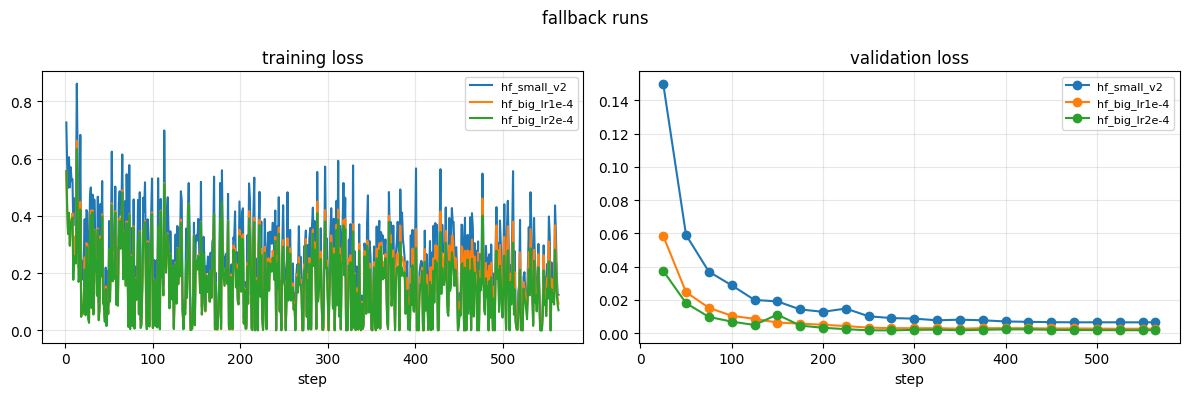

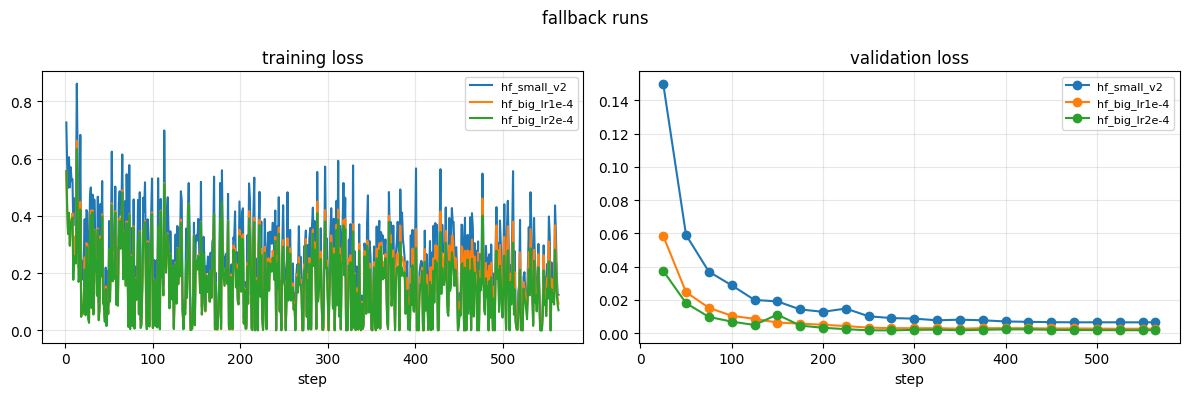

In [7]:
sprint.ALLOW_HF_FALLBACK = False
sprint.set_backend("hf")                      # scripts/train_hf.py for every run in this notebook
HP = {"training": {"epochs": 3, "seed": 42, "lora": {"r": 16, "alpha": 32, "dropout": 0.05}},
      "data": {"train": "./data/train.jsonl", "replay": "./data/replay.jsonl"}}
SMALL_RUN = "hf_small_v2"
LRS = {"hf_big_lr1e-4": 1e-4, "hf_big_lr2e-4": 2e-4}
PLAN = {SMALL_RUN: (SMALL, 2e-4), **{n: (BIG, lr) for n, lr in LRS.items()}}

META, VAL = {}, {}
for name, (base, lr) in PLAN.items():
    path, cfg = sprint.make_config(name, sprint.deep_merge(HP, {"base": base, "training": {"lr": lr}}))
    META[name] = sprint.train(name, path, cfg)                  # skipped if the adapter is already on Drive
    predict(name, "val", adapter=f"runs/{name}", base=base)
    VAL[name] = sprint.score(name, "val", vs=None if base == SMALL else "base_1p7b")
    sprint.log_result(name, "val", VAL[name], sprint.settings(cfg), notes=f"fallback; base={base.split('/')[-1]}")
sprint.plot_losses(list(PLAN), title="fallback runs", save_as="loss_fallback.png")

In [8]:
# ---- Phase 2 checks and the frozen choice
check("F2.1", all(m.get("backend") == "hf" for m in META.values()), f"backends={ {n: m.get('backend') for n, m in META.items()} }")
ok, parts = True, []
for n in PLAN:
    h = sprint.loss_history(f"runs/{n}")
    tr = [l for _, l in h["train"]]; va = [l for _, l in h["eval"]]
    k = max(1, len(tr) // 4)
    good = len(tr) > 1 and all(math.isfinite(l) for l in tr) and sum(tr[-k:]) / k < sum(tr[:k]) / k and len(va) > 0
    ok &= good
    parts.append(f"{n}: train {sum(tr[:k]) / k:.3f}->{sum(tr[-k:]) / k:.3f}, val min {min(va):.4f}" if tr and va else f"{n}: no loss")
check("F2.2", ok, "; ".join(parts))
check("F2.3", all(VAL[n]["paired_a_minus_b"]["ci95"][0] > 0 for n in LRS),
      "; ".join(f"{n}: {VAL[n]['metrics']['exact_match']}% vs base {VAL[n]['paired_a_minus_b']['exact_match_diff']:+} "
                f"{VAL[n]['paired_a_minus_b']['ci95']}" for n in LRS))
gold_val = ev.load_jsonl("data/eval/val.jsonl")
vs_soup_val = {}
for n in LRS:
    soup_twin = n.replace("hf_", "")                            # hf_big_lr1e-4 -> big_lr1e-4
    rep, _ = ev.evaluate(gold_val, ev.load_preds(sprint.pred_path(n, "val")), ev.load_preds(sprint.pred_path(soup_twin, "val")))
    vs_soup_val[n] = rep["paired_a_minus_b"]
check("F2.4", None, "; ".join(f"{n} - Soup: {p['exact_match_diff']:+} {p['ci95']}" for n, p in vs_soup_val.items()))

if os.path.exists("reports/test_lock_hf.json"):
    frozen_hf = json.load(open("reports/best_run_hf.json")); print("already frozen:", frozen_hf)
else:
    em = {n: VAL[n]["metrics"]["exact_match"] for n in LRS}
    a, b = em["hf_big_lr1e-4"], em["hf_big_lr2e-4"]
    best = "hf_big_lr1e-4" if (a >= b or b - a < 2.0) else "hf_big_lr2e-4"
    frozen_hf = {"run": best, "lr": LRS[best], "val_all": em, "frozen_at": time.strftime("%Y-%m-%d %H:%M:%S")}
    json.dump(frozen_hf, open("reports/best_run_hf.json", "w"), indent=2); print("frozen:", frozen_hf)
HF_BEST = frozen_hf["run"]
check("F2.5", os.path.exists("reports/best_run_hf.json"), f"HF_BEST={HF_BEST} frozen at {frozen_hf['frozen_at']}")

✅ PASS   F2.1  backends={'hf_small_v2': 'hf', 'hf_big_lr1e-4': 'hf', 'hf_big_lr2e-4': 'hf'}
✅ PASS   F2.2  hf_small_v2: train 0.307->0.213, val min 0.0065; hf_big_lr1e-4: train 0.221->0.166, val min 0.0026; hf_big_lr2e-4: train 0.213->0.132, val min 0.0017
✅ PASS   F2.3  hf_big_lr1e-4: 88.33% vs base +86.67 [82.67, 90.33]; hf_big_lr2e-4: 88.67% vs base +87.0 [83.33, 90.67]
👀 REVIEW F2.4  hf_big_lr1e-4 - Soup: +0.67 [-2.0, 3.33]; hf_big_lr2e-4 - Soup: -0.33 [-3.33, 2.67]
frozen: {'run': 'hf_big_lr1e-4', 'lr': 0.0001, 'val_all': {'hf_big_lr1e-4': 88.33, 'hf_big_lr2e-4': 88.67}, 'frozen_at': '2026-11-11 21:45:29'}
✅ PASS   F2.5  HF_BEST=hf_big_lr1e-4 frozen at 2026-11-11 21:45:29


True

## Phase 3 — Test and stress, once (≈ 5 min)

**Acceptance checks, set before seeing any results:**

| # | Check | Pass when |
|---|---|---|
| F3.1 | Task win | test: `HF_BEST` beats the untouched 1.7B by ≥ 10 points, paired CI95 above 0 |
| F3.2 | Format | parse_strict ≥ 95% on test and stress |
| F3.3 | Trainer effect at 1.7B | 👀 `HF_BEST` − Soup `big_lr1e-4`, test and stress (paired) |
| F3.4 | Size effect, clean | 👀 test: `HF_BEST` − `hf_small_v2` (paired; same data, same trainer) |
| F3.5 | Size effect, stress | 👀 stress: `HF_BEST` − `hf_small_v2`, overall and per group |
| F3.6 | Gap | `HF_BEST`: test − stress ≤ 15 points |
| F3.7 | Honest process | test/stress run once, after `HF_BEST` was frozen |

In [9]:
lock_path = "reports/test_lock_hf.json"
if not os.path.exists(lock_path):
    json.dump({"run": HF_BEST, "first_test_at": time.strftime("%Y-%m-%d %H:%M:%S"), "best_frozen_at": frozen_hf["frozen_at"]},
              open(lock_path, "w"), indent=2)
lock_hf = json.load(open(lock_path)); print("lock:", lock_hf)

FINAL = {}
for split in ["test", "stress"]:
    predict(HF_BEST, split, adapter=f"runs/{HF_BEST}")
    predict(SMALL_RUN, split, adapter=f"runs/{SMALL_RUN}", base=SMALL)
    sprint.log_result(f"FINAL {SMALL_RUN}", split, sprint.score(SMALL_RUN, split), notes="360M, fallback, v2 data")
    FINAL[(split, "soup")] = sprint.score(HF_BEST, split, vs="big_lr1e-4")
    sprint.log_result("FINAL hf 1.7B vs Soup 1.7B", split, FINAL[(split, "soup")], notes=f"{HF_BEST} vs big_lr1e-4")
    FINAL[(split, "small")] = sprint.score(HF_BEST, split, vs=SMALL_RUN)
    sprint.log_result("FINAL hf 1.7B vs hf 360M", split, FINAL[(split, "small")], notes=f"{HF_BEST} vs {SMALL_RUN}")
    FINAL[(split, "base")] = sprint.score(HF_BEST, split, vs="base_1p7b")       # saved report = vs the 1.7B base
    sprint.log_result("FINAL hf 1.7B vs base", split, FINAL[(split, "base")], notes=f"{HF_BEST} vs untouched 1.7B")

lock: {'run': 'hf_big_lr1e-4', 'first_test_at': '2026-11-11 21:45:29', 'best_frozen_at': '2026-11-11 21:45:29'}
$ /usr/bin/python3 scripts/predict.py --base HuggingFaceTB/SmolLM2-1.7B-Instruct --input data/eval/test.jsonl --output /content/drive/MyDrive/soup-sprint-1p7b/reports/preds/hf_big_lr1e-4_test.pred.jsonl --batch-size 32 --adapter runs/hf_big_lr1e-4

Loading weights: 100%|██████████| 218/218 [00:00<00:00, 6580.15it/s]
loaded adapter from runs/hf_big_lr1e-4
300 rows in 35.5s on cuda -> /content/drive/MyDrive/soup-sprint-1p7b/reports/preds/hf_big_lr1e-4_test.pred.jsonl
$ /usr/bin/python3 scripts/predict.py --base HuggingFaceTB/SmolLM2-360M-Instruct --input data/eval/test.jsonl --output /content/drive/MyDrive/soup-sprint-1p7b/reports/preds/hf_small_v2_test.pred.jsonl --batch-size 32 --adapter runs/hf_small_v2

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 4534.81it/s]
loaded adapter from runs/hf_small_v2
300 rows in 47.9s on cuda -> /content/drive/MyDrive/soup-sprint-1p7

In [ ]:
# ---- stress by group and wording tier: 360M (hf) vs Soup 1.7B vs hf 1.7B
gold_st = ev.load_jsonl("data/eval/stress.jsonl")
P = {n: ev.load_preds(sprint.pred_path(n, "stress")) for n in [SMALL_RUN, "big_lr1e-4", HF_BEST]}
G = {n: bd.by_group(gold_st, p) for n, p in P.items()}
G_vs_small = bd.by_group(gold_st, P[HF_BEST], P[SMALL_RUN])
print(f"  {'group':12s} {'n':>4s} {'360M hf':>9s} {'1.7B Soup':>10s} {'1.7B hf':>9s}   hf 1.7B - 360M [CI95]")
for g, r in G_vs_small.items():
    q = r["paired_a_minus_b"]
    print(f"  {g:12s} {r['n']:4d} {G[SMALL_RUN][g]['exact_match']:8.1f}% {G['big_lr1e-4'][g]['exact_match']:9.1f}% "
          f"{r['exact_match']:8.1f}%   {q['exact_match_diff']:+.1f} {q['ci95']}")
T = {n: bd.field_by_tier(gold_st, p) for n, p in P.items()}
print("\n  field/tier            n   360M hf  1.7B Soup  1.7B hf")
for k in T[HF_BEST]:
    print(f"  {k:18s} {T[HF_BEST][k]['n']:4d} {T[SMALL_RUN][k]['accuracy']:8.1f}% {T['big_lr1e-4'][k]['accuracy']:9.1f}% {T[HF_BEST][k]['accuracy']:8.1f}%")
json.dump({"groups": G, "hf_vs_small": G_vs_small, "tiers": T}, open("reports/stress_breakdown_hf.json", "w"), indent=2)

In [ ]:
# ---- Phase 3 checks
def verdict(q, a, b):
    return f"{a} better" if q["ci95"][0] > 0 else (f"{b} better" if q["ci95"][1] < 0 else "no clear difference")

t, s = FINAL[("test", "base")], FINAL[("stress", "base")]
p = t["paired_a_minus_b"]
check("F3.1", p["exact_match_diff"] >= 10 and p["ci95"][0] > 0,
      f"test {t['metrics']['exact_match']}% vs untouched 1.7B {t['b']['metrics']['exact_match']}%: {p['exact_match_diff']:+} {p['ci95']}")
check("F3.2", t["metrics"]["parse_strict"] >= 95 and s["metrics"]["parse_strict"] >= 95,
      f"parse_strict test {t['metrics']['parse_strict']}%, stress {s['metrics']['parse_strict']}%")
check("F3.3", None, "; ".join(
      f"{sp}: hf {FINAL[(sp, 'soup')]['metrics']['exact_match']}% vs Soup {FINAL[(sp, 'soup')]['b']['metrics']['exact_match']}% "
      f"= {FINAL[(sp, 'soup')]['paired_a_minus_b']['exact_match_diff']:+} {FINAL[(sp, 'soup')]['paired_a_minus_b']['ci95']} "
      f"-> {verdict(FINAL[(sp, 'soup')]['paired_a_minus_b'], 'fallback', 'Soup')}" for sp in ["test", "stress"]))
for cid, sp in [("F3.4", "test"), ("F3.5", "stress")]:
    r = FINAL[(sp, "small")]; q = r["paired_a_minus_b"]
    extra = ("; by group: " + ", ".join(f"{g} {v['paired_a_minus_b']['exact_match_diff']:+.1f} {v['paired_a_minus_b']['ci95']}"
                                         for g, v in G_vs_small.items())) if sp == "stress" else ""
    check(cid, None, f"{sp}: 1.7B {r['metrics']['exact_match']}% vs 360M {r['b']['metrics']['exact_match']}% = "
                     f"{q['exact_match_diff']:+} {q['ci95']} -> {verdict(q, '1.7B', '360M')}{extra}")
gap = t["metrics"]["exact_match"] - s["metrics"]["exact_match"]
check("F3.6", gap <= 15, f"test - stress = {gap:.1f} points (Soup 1.7B: 14.7)")
check("F3.7", lock_hf["run"] == HF_BEST and lock_hf["best_frozen_at"] == frozen_hf["frozen_at"],
      f"test first run at {lock_hf['first_test_at']} with {lock_hf['run']}")
sprint.show_errors(HF_BEST, "stress", n=10)

## Phase 4 — IFEval and HellaSwag (≈ 30–45 min)

Only the new 1.7B is evaluated; every other row is read from the results the 1.7B run saved
(`lm_eval` finds them and does not run again).

| # | Check | Pass when |
|---|---|---|
| F4.1 | Above the 360M | `HF_BEST` beats the tuned 360M on IFEval **and** HellaSwag by more than 1.96 × the combined standard error |
| F4.2 | No forgetting | `HF_BEST` drops ≤ 5 points from the untouched 1.7B on each |
| F4.3 | Trainer effect | 👀 `HF_BEST` vs the Soup 1.7B on each |

In [12]:
LM = {
    "360M untouched": lm_eval("v1_base_360m", copy_from=os.path.join(V1_PROJECT, "reports/lm_eval/base")),
    "360M tuned (ep_3, fallback)": lm_eval("v1_ep3_360m", copy_from=os.path.join(V1_PROJECT, "reports/lm_eval/best")),
    "1.7B untouched": lm_eval("base_1p7b"),
    "1.7B tuned (Soup)": lm_eval("best_1p7b", adapter_dir=sprint.find_adapter("runs/big_lr1e-4")),
    "1.7B tuned (fallback)": lm_eval("hf_best_1p7b", adapter_dir=sprint.find_adapter(f"runs/{HF_BEST}")),
}
json.dump(LM, open("reports/lm_eval_summary_hf.json", "w"), indent=2)
print(f"{'model':28s} " + "  ".join(f"{t:>16s}" for t in TASKS))
for m, sc in LM.items():
    print(f"{m:28s} " + ("  ".join(f"{sc[t][0]:8.2f} ± {sc[t][1] or float('nan'):5.2f}" for t in TASKS) if sc else "not available"))

$ /usr/bin/python3 -m lm_eval --model hf --model_args pretrained=HuggingFaceTB/SmolLM2-1.7B-Instruct,dtype=bfloat16,peft=runs/hf_big_lr1e-4 --tasks ifeval --batch_size auto --output_path reports/lm_eval/hf_best_1p7b_ifeval --seed 0 --apply_chat_template
$ /usr/bin/python3 -m lm_eval --model hf --model_args pretrained=HuggingFaceTB/SmolLM2-1.7B-Instruct,dtype=bfloat16,peft=runs/hf_big_lr1e-4 --tasks hellaswag --batch_size auto --output_path reports/lm_eval/hf_best_1p7b_hellaswag --seed 0
model                                  ifeval         hellaswag
360M untouched                  33.09 ±  2.02     56.74 ±  0.49
360M tuned (ep_3, fallback)     31.61 ±  2.00     57.04 ±  0.49
1.7B untouched                  47.13 ±  2.15     71.72 ±  0.45
1.7B tuned (Soup)               48.98 ±  2.15     71.53 ±  0.45
1.7B tuned (fallback)           49.91 ±  2.15     71.53 ±  0.45


In [ ]:
# ---- Phase 4 checks
new, base17, soup17, small = LM["1.7B tuned (fallback)"], LM["1.7B untouched"], LM["1.7B tuned (Soup)"], LM["360M tuned (ep_3, fallback)"]
if small:
    g = {t: z(new[t], small[t]) for t in TASKS}
    check("F4.1", all(d > 0 and zz is not None and zz > 1.96 for d, zz in g.values()),
          ", ".join(f"{t} {new[t][0]} vs {small[t][0]} ({d:+}, z={zz})" for t, (d, zz) in g.items()))
else:
    check("F4.1", None, "360M results not found")
drops = {t: round(base17[t][0] - new[t][0], 2) for t in TASKS}
check("F4.2", all(d <= 5 for d in drops.values()), ", ".join(f"{t} {base17[t][0]} -> {new[t][0]} ({-d:+})" for t, d in drops.items()))
check("F4.3", None, ", ".join(f"{t}: fallback - Soup {z(new[t], soup17[t])[0]:+} (z={z(new[t], soup17[t])[1]})" for t in TASKS))

### Results summary

In [14]:
br = json.load(open("reports/stress_breakdown_hf.json"))
row = lambda r: f"{r['metrics']['exact_match']}% {r['metrics']['exact_match_ci95']}"
lines = ["# Results — 1.7B with the fallback trainer", "",
         f"HF_BEST: `{HF_BEST}` (lr {frozen_hf['lr']}, val {frozen_hf['val_all']}); 360M reference `{SMALL_RUN}`; "
         "all trained with scripts/train_hf.py on the v2 data, 3 epochs, LoRA r16, seed 42.", "",
         "| | test | stress |", "|---|---|---|",
         f"| 1.7B fallback (`{HF_BEST}`) | {row(FINAL[('test', 'base')])} | {row(FINAL[('stress', 'base')])} |",
         f"| 1.7B Soup (`big_lr1e-4`) | {FINAL[('test', 'soup')]['b']['metrics']['exact_match']}% | {FINAL[('stress', 'soup')]['b']['metrics']['exact_match']}% |",
         f"| 360M fallback (`{SMALL_RUN}`) | {FINAL[('test', 'small')]['b']['metrics']['exact_match']}% | {FINAL[('stress', 'small')]['b']['metrics']['exact_match']}% |",
         "", "| paired difference | test | stress |", "|---|---|---|"]
for key, label in [("soup", "fallback − Soup (1.7B)"), ("small", "1.7B − 360M (fallback)"), ("base", "tuned − untouched 1.7B")]:
    lines.append(f"| {label} | " + " | ".join(f"{FINAL[(sp, key)]['paired_a_minus_b']['exact_match_diff']:+} "
                                               f"{FINAL[(sp, key)]['paired_a_minus_b']['ci95']}" for sp in ["test", "stress"]) + " |")
lines += ["", "## LoRA layers", "", "| adapter | target_modules | MB |", "|---|---|---|"]
LORA[f"fallback 1.7B ({HF_BEST})"] = lora_info(f"runs/{HF_BEST}")
lines += [f"| {k} | {v['target_modules']} | {v['adapter_mb']} |" for k, v in LORA.items() if v]
lines += ["", "## IFEval and HellaSwag (score ± standard error)", "", "| model | " + " | ".join(TASKS) + " |",
          "|---|" + "---|" * len(TASKS)]
lines += [f"| {m} | " + " | ".join(f"{sc[t][0]} ± {sc[t][1]}" for t in TASKS) + " |" for m, sc in LM.items() if sc]
open("reports/RESULTS_fallback.md", "w", encoding="utf-8").write("\n".join(lines))
print("\n".join(lines))
print()
checks_all = json.load(open("reports/checks.json"))
for cid in sorted(c for c in checks_all if c.startswith("F")):
    print(f"{checks_all[cid]['status']:6s} {cid:5s} {checks_all[cid]['detail'][:120]}")

# Results — 1.7B with the fallback trainer

HF_BEST: `hf_big_lr1e-4` (lr 0.0001, val {'hf_big_lr1e-4': 88.33, 'hf_big_lr2e-4': 88.67}); 360M reference `hf_small_v2`; all trained with scripts/train_hf.py on the v2 data, 3 epochs, LoRA r16, seed 42.

| | test | stress |
|---|---|---|
| 1.7B fallback (`hf_big_lr1e-4`) | 96.67% [94.33, 98.67] | 80.33% [75.67, 84.67] |
| 1.7B Soup (`big_lr1e-4`) | 93.67% | 79.0% |
| 360M fallback (`hf_small_v2`) | 88.67% | 67.67% |

| paired difference | test | stress |
|---|---|---|
| fallback − Soup (1.7B) | +3.0 [0.67, 5.33] | +1.33 [-2.0, 5.0] |
| 1.7B − 360M (fallback) | +8.0 [4.67, 11.33] | +12.67 [7.67, 17.67] |
| tuned − untouched 1.7B | +94.67 [92.0, 97.0] | +80.33 [75.67, 84.67] |

## LoRA layers

| adapter | target_modules | MB |
|---|---|---|
| Soup 1.7B (big_lr1e-4) | ['q_proj', 'v_proj'] | 12.0 |
| fallback 360M (ep_3) | ['down_proj', 'gate_proj', 'k_proj', 'o_proj', 'q_proj', 'up_proj', 'v_proj'] | 33.2 |
| fallback 1.7B (hf_big_lr1e-4) | ['d

**Done → Runtime → Disconnect and delete runtime.** The new adapters are in `MyDrive/soup-sprint-1p7b/runs/hf_*`;
the summary is `reports/RESULTS_fallback.md`.